# Alpha Diversity - Comparing Groups

Hypothesis Testing (ANOVA/Kruskal-Wallis): If you have categorical treatments (e.g., Control vs. Impact, High Altitude vs. Low Altitude), use parametric (ANOVA) or non-parametric (Kruskal-Wallis) tests to see if the richness or evenness significantly differs between groups.
Post-hoc Testing: If an ANOVA is significant, perform Tukey’s HSD or Dunn’s test to identify exactly which pairs of sites are different.

In [1]:
# Load shared R functions for the Oulanka datasets.
source("../src/oulanka.R")

In [2]:
# Load genus-level saproxylic community data
saproxylic_community_df <- get_saproxylic_community_data(genus=TRUE)
# Load environment data
environment_df <- get_environment_data()

In [3]:
# library(vegan)
# library(tidyverse)

## 1. Prepare data

In [4]:
community_data <- as.matrix(saproxylic_community_df)
rownames(community_data) <- environment_df$Sample.Number

In [5]:
head(community_data)

,Aotearoamyces,Arachnopeziza,Ascocoryne,Atheliachaete,Botryobasidium,Ceraceomyces,Cistella,Claussenomyces,Collophora,Coniophora,⋯,Serpula,Sistotremastrum,Skvortzovia,Stereum,Teichospora,Trametes,Trechispora,Tympanis,Xenasmatella,Xylaria
018561A,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
018561C,0,1,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
018561E,0,0,0,0,0,0,0,0,0,0,⋯,7,0,0,0,0,0,0,0,0,0
018562C,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
018562E,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
018579B,0,0,0,0,0,0,0,0,0,0,⋯,2,0,0,0,0,0,0,0,0,0


In [6]:
metadata <- environment_df %>%
    select(Sample.Number, Transect, Wood.Type, Wood.Texture)

In [7]:
head(metadata)

Sample.Number,Transect,Wood.Type,Wood.Texture
<chr>,<chr>,<chr>,<chr>
018561A,A,Pine,Softwood
018561C,A,Birch,Hardwood
018561E,A,Spruce,Softwood
018562C,A,Birch,Hardwood
018562E,A,Spruce,Softwood
018579B,A,Pine,Softwood


## 2. Calculate diversity indices

In [8]:
# Richness (number of species present)
richness <- specnumber(community_data)

# Shannon Index (Evenness/Diversity)
shannon <- diversity(community_data, index = "shannon")

# Simpson Index (Dominance/Evenness)
simpson <- diversity(community_data, index = "simpson")

# Combine into a single dataframe for analysis
analysis_df <- metadata %>%
  mutate(richness = richness,
         shannon = shannon,
         simpson = simpson)

head(analysis_df)

Sample.Number,Transect,Wood.Type,Wood.Texture,richness,shannon,simpson
<chr>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>
018561A,A,Pine,Softwood,1,0.0000000,0.0000000
018561C,A,Birch,Hardwood,5,0.8442732,0.4104142
018561E,A,Spruce,Softwood,2,0.3767702,0.2187500
018562C,A,Birch,Hardwood,1,0.0000000,0.0000000
018562E,A,Spruce,Softwood,1,0.0000000,0.0000000
018579B,A,Pine,Softwood,3,0.8486856,0.4938272


## 3. Statistical Comparison and Visualization

### 3.1. Transect

#### 3.1.1. Statistical test - Species richness

In [9]:
# Check for normality (Shapiro-Wilk test)
# If p > 0.05, use ANOVA. If p < 0.05, use Kruskal-Wallis.
shapiro_test <- shapiro.test(analysis_df$richness)

p.value <- NULL
if(shapiro_test$p.value > 0.05) {
    # Parametric approach: ANOVA
    print("Parameteric")
    stat_result <- aov(richness ~ Transect, data = analysis_df)
    p.value <- summary(res)[[1]]["Pr(>F)", ]
    summary(stat_result)
} else {
    print("Non-parameteric")
    # Non-parametric approach: Kruskal-Wallis
    stat_result <- kruskal.test(richness ~ Transect, data = analysis_df)
    p.value <- stat_result$p.value
    print(stat_result)
}

[1] "Non-parameteric"

	Kruskal-Wallis rank sum test

data:  richness by Transect
Kruskal-Wallis chi-squared = 1.0948, df = 2, p-value = 0.5785



#### 3.1.2 Visualization - Species richness

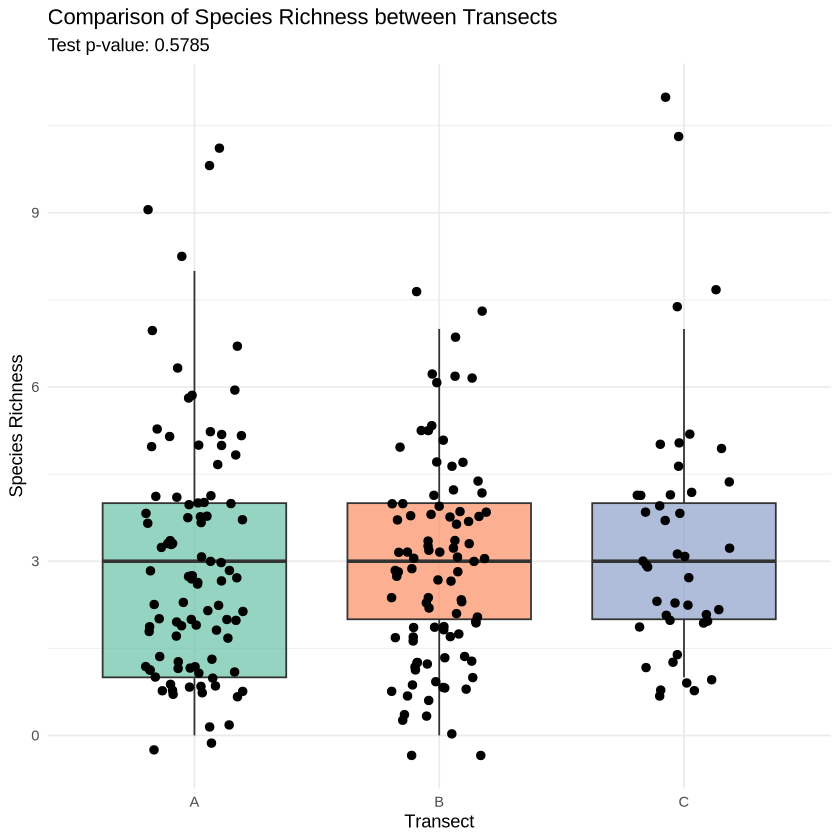

In [10]:
ggplot(analysis_df, aes(x = Transect, y = richness, fill = Transect)) +
  geom_boxplot(alpha = 0.7, outlier.shape = NA) +
  geom_jitter(width = 0.2, size = 2) + # Show individual data points
  theme_minimal() +
  labs(title = "Comparison of Species Richness between Transects",
       subtitle = paste("Test p-value:", round(p.value, 4)),
       x = "Transect",
       y = "Species Richness") +
  scale_fill_brewer(palette = "Set2") +
  theme(legend.position = "none")

#### 3.1.3. Statistical test - Shannon diversity

In [11]:
# Check for normality (Shapiro-Wilk test)
# If p > 0.05, use ANOVA. If p < 0.05, use Kruskal-Wallis.
shapiro_test <- shapiro.test(analysis_df$shannon)

p.value <- NULL
if(shapiro_test$p.value > 0.05) {
    # Parametric approach: ANOVA
    print("Parameteric")
    stat_result <- aov(shannon ~ Transect, data = analysis_df)
    p.value <- summary(res)[[1]]["Pr(>F)", ]
    summary(stat_result)
} else {
    print("Non-parameteric")
    # Non-parametric approach: Kruskal-Wallis
    stat_result <- kruskal.test(shannon ~ Transect, data = analysis_df)
    p.value <- stat_result$p.value
    print(stat_result)
}

[1] "Non-parameteric"

	Kruskal-Wallis rank sum test

data:  shannon by Transect
Kruskal-Wallis chi-squared = 0.96518, df = 2, p-value = 0.6172



#### 3.1.4 Visualization - Shannon diversity

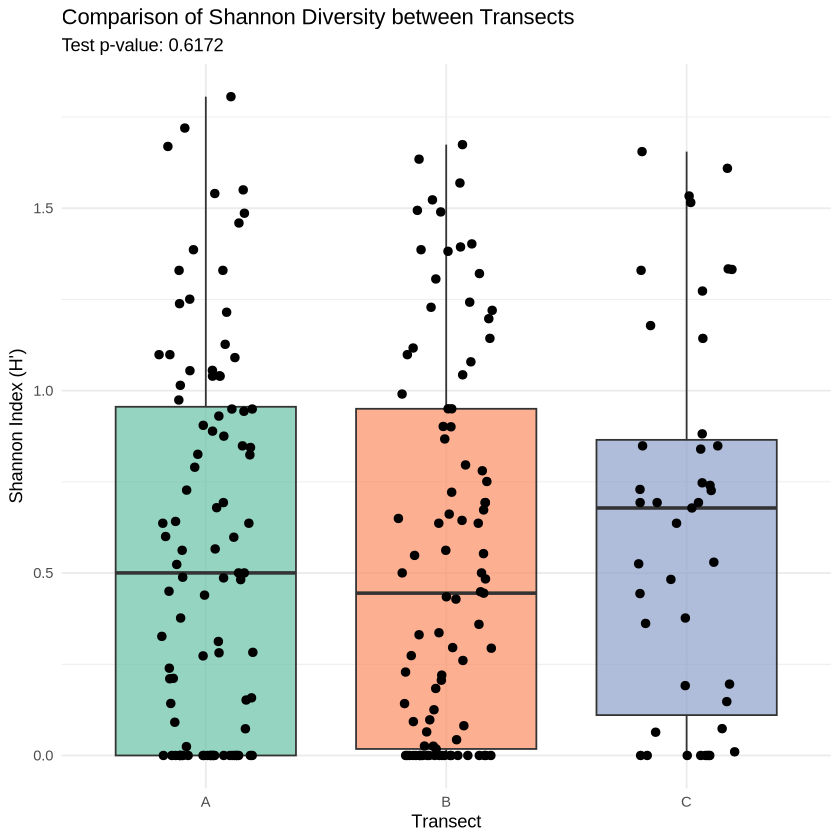

In [12]:
ggplot(analysis_df, aes(x = Transect, y = shannon, fill = Transect)) +
  geom_boxplot(alpha = 0.7, outlier.shape = NA) +
  geom_jitter(width = 0.2, size = 2) + # Show individual data points
  theme_minimal() +
  labs(title = "Comparison of Shannon Diversity between Transects",
       subtitle = paste("Test p-value:", round(p.value, 4)),
       x = "Transect",
       y = "Shannon Index (H')") +
  scale_fill_brewer(palette = "Set2") +
  theme(legend.position = "none")

#### 3.1.5. Statistical test - Simpson diversity

In [13]:
# Check for normality (Shapiro-Wilk test)
# If p > 0.05, use ANOVA. If p < 0.05, use Kruskal-Wallis.
shapiro_test <- shapiro.test(analysis_df$simpson)

p.value <- NULL
if(shapiro_test$p.value > 0.05) {
    # Parametric approach: ANOVA
    print("Parameteric")
    stat_result <- aov(simpson ~ Transect, data = analysis_df)
    p.value <- summary(res)[[1]]["Pr(>F)", ]
    summary(stat_result)
} else {
    print("Non-parameteric")
    # Non-parametric approach: Kruskal-Wallis
    stat_result <- kruskal.test(simpson ~ Transect, data = analysis_df)
    p.value <- stat_result$p.value
    print(stat_result)
}

[1] "Non-parameteric"

	Kruskal-Wallis rank sum test

data:  simpson by Transect
Kruskal-Wallis chi-squared = 0.26618, df = 2, p-value = 0.8754



#### 3.1.6. Visualization - Simpson diversity

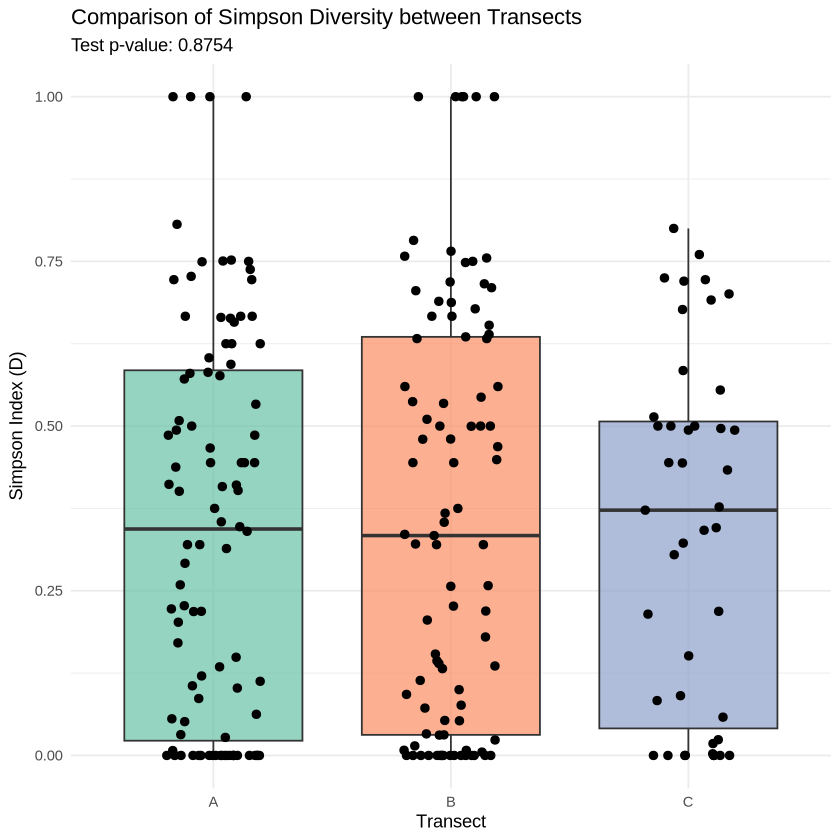

In [14]:
ggplot(analysis_df, aes(x = Transect, y = simpson, fill = Transect)) +
  geom_boxplot(alpha = 0.7, outlier.shape = NA) +
  geom_jitter(width = 0.2, size = 2) + # Show individual data points
  theme_minimal() +
  labs(title = "Comparison of Simpson Diversity between Transects",
       subtitle = paste("Test p-value:", round(p.value, 4)),
       x = "Transect",
       y = "Simpson Index (D)") +
  scale_fill_brewer(palette = "Set2") +
  theme(legend.position = "none")

### 3.2. Transect + Wood.Texture

#### 3.2.1. Statistical test - Species richness

In [15]:
# Check for normality (Shapiro-Wilk test)
# If p > 0.05, use ANOVA. If p < 0.05, use Kruskal-Wallis.
shapiro_test <- shapiro.test(analysis_df$richness)

p.value <- NULL
if(shapiro_test$p.value > 0.05) {
    # Parametric approach: ANOVA
    print("Parameteric")
    stat_result <- aov(richness ~ Transect * Wood.Texture, data = analysis_df)
    p.value <- summary(res)[[1]]["Pr(>F)", ]
    summary(stat_result)
} else {
    print("Non-parameteric")
    # Non-parametric approach: Kruskal-Wallis
    stat_result <- kruskal.test(richness ~ interaction(Transect, Wood.Texture), data = analysis_df)
    p.value <- stat_result$p.value
    print(stat_result)
}

[1] "Non-parameteric"

	Kruskal-Wallis rank sum test

data:  richness by interaction(Transect, Wood.Texture)
Kruskal-Wallis chi-squared = 2.2142, df = 5, p-value = 0.8188



#### 3.2.2 Visualization - Species richness

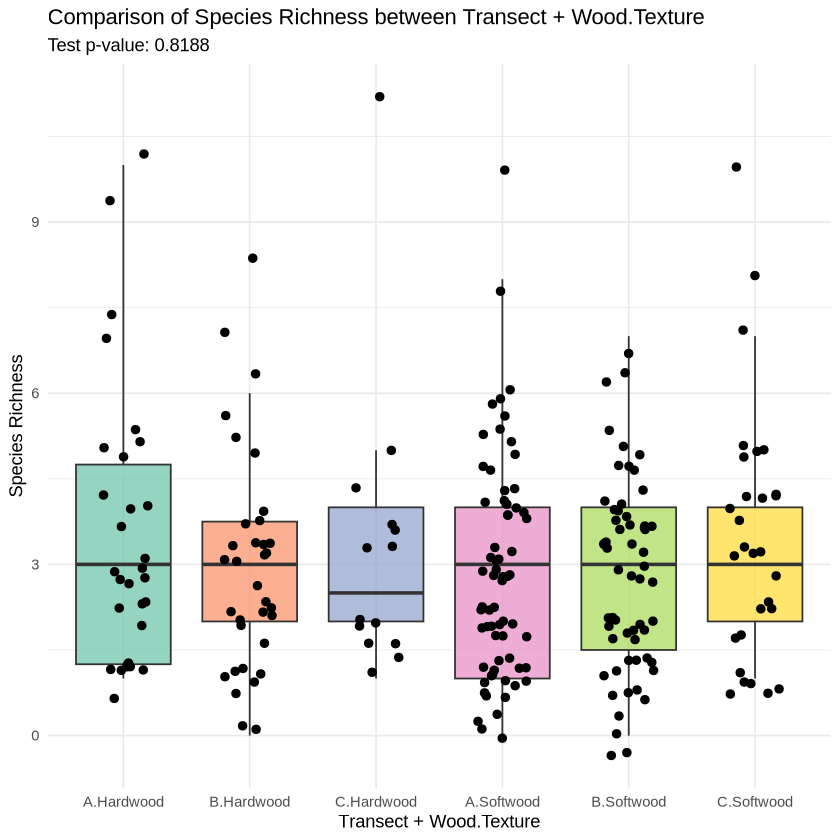

In [16]:
ggplot(analysis_df, aes(x = interaction(Transect, Wood.Texture), y = richness, fill = interaction(Transect, Wood.Texture))) +
  geom_boxplot(alpha = 0.7, outlier.shape = NA) +
  geom_jitter(width = 0.2, size = 2) + # Show individual data points
  theme_minimal() +
  labs(title = "Comparison of Species Richness between Transect + Wood.Texture",
       subtitle = paste("Test p-value:", round(p.value, 4)),
       x = "Transect + Wood.Texture",
       y = "Species Richness") +
  scale_fill_brewer(palette = "Set2") +
  theme(legend.position = "none")

#### 3.2.3. Statistical test - Shannon diversity

In [17]:
# Check for normality (Shapiro-Wilk test)
# If p > 0.05, use ANOVA. If p < 0.05, use Kruskal-Wallis.
shapiro_test <- shapiro.test(analysis_df$shannon)

p.value <- NULL
if(shapiro_test$p.value > 0.05) {
    # Parametric approach: ANOVA
    print("Parameteric")
    stat_result <- aov(shannon ~ Transect * Wood.Texture, data = analysis_df)
    p.value <- summary(res)[[1]]["Pr(>F)", ]
    summary(stat_result)
} else {
    print("Non-parameteric")
    # Non-parametric approach: Kruskal-Wallis
    stat_result <- kruskal.test(shannon ~ interaction(Transect, Wood.Texture), data = analysis_df)
    p.value <- stat_result$p.value
    print(stat_result)
}

[1] "Non-parameteric"

	Kruskal-Wallis rank sum test

data:  shannon by interaction(Transect, Wood.Texture)
Kruskal-Wallis chi-squared = 2.6791, df = 5, p-value = 0.7493



#### 3.2.4. Visualization - Shannon diversity

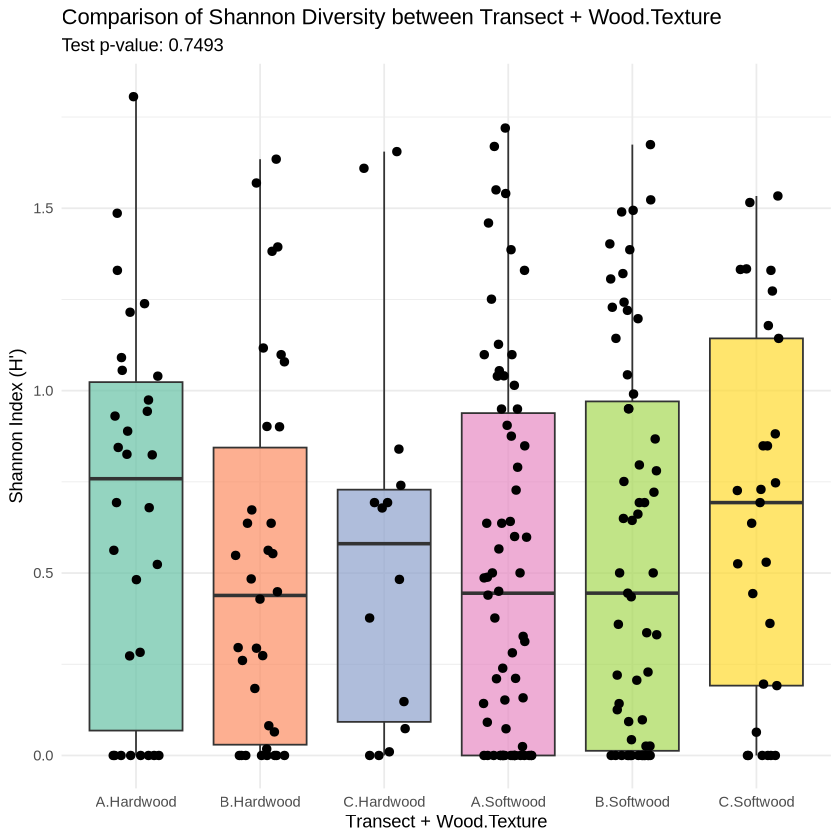

In [18]:
ggplot(analysis_df, aes(x = interaction(Transect, Wood.Texture), y = shannon, fill = interaction(Transect, Wood.Texture))) +
  geom_boxplot(alpha = 0.7, outlier.shape = NA) +
  geom_jitter(width = 0.2, size = 2) + # Show individual data points
  theme_minimal() +
  labs(title = "Comparison of Shannon Diversity between Transect + Wood.Texture",
       subtitle = paste("Test p-value:", round(p.value, 4)),
       x = "Transect + Wood.Texture",
       y = "Shannon Index (H')") +
  scale_fill_brewer(palette = "Set2") +
  theme(legend.position = "none")

#### 3.2.5. Statistical test - Simpson diversity

In [19]:
# Check for normality (Shapiro-Wilk test)
# If p > 0.05, use ANOVA. If p < 0.05, use Kruskal-Wallis.
shapiro_test <- shapiro.test(analysis_df$simpson)

p.value <- NULL
if(shapiro_test$p.value > 0.05) {
    # Parametric approach: ANOVA
    print("Parameteric")
    stat_result <- aov(simpson ~ Transect * Wood.Texture, data = analysis_df)
    p.value <- summary(res)[[1]]["Pr(>F)", ]
    summary(stat_result)
} else {
    print("Non-parameteric")
    # Non-parametric approach: Kruskal-Wallis
    stat_result <- kruskal.test(simpson ~ interaction(Transect, Wood.Texture), data = analysis_df)
    p.value <- stat_result$p.value
    print(stat_result)
}

[1] "Non-parameteric"

	Kruskal-Wallis rank sum test

data:  simpson by interaction(Transect, Wood.Texture)
Kruskal-Wallis chi-squared = 0.74904, df = 5, p-value = 0.9802



#### 3.2.6. Visualization - Simpson diversity

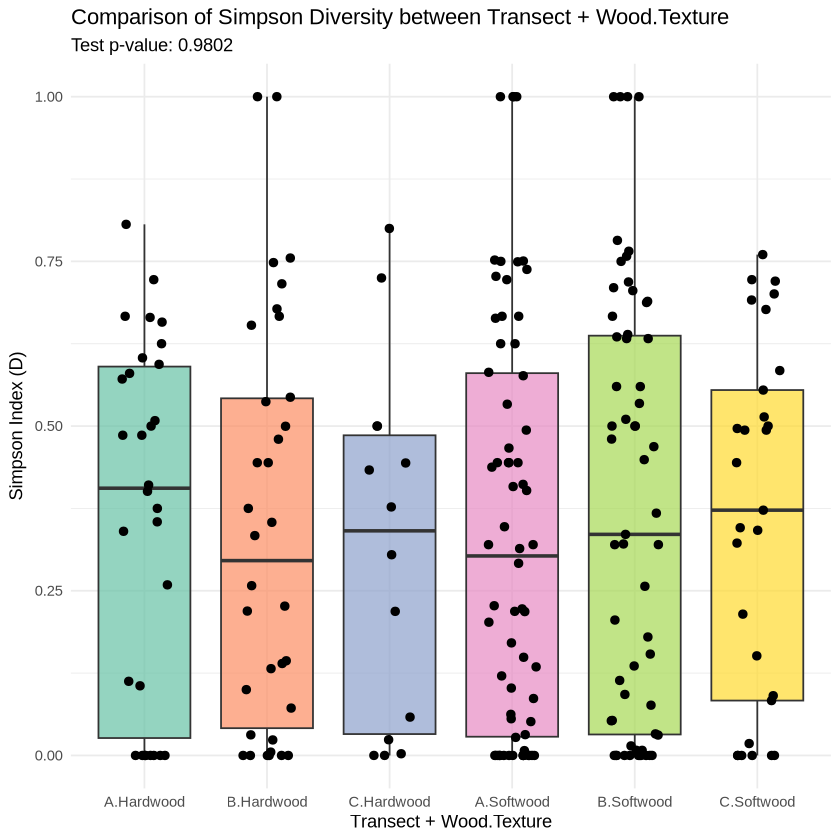

In [20]:
ggplot(analysis_df, aes(x = interaction(Transect, Wood.Texture), y = simpson, fill = interaction(Transect, Wood.Texture))) +
  geom_boxplot(alpha = 0.7, outlier.shape = NA) +
  geom_jitter(width = 0.2, size = 2) + # Show individual data points
  theme_minimal() +
  labs(title = "Comparison of Simpson Diversity between Transect + Wood.Texture",
       subtitle = paste("Test p-value:", round(p.value, 4)),
       x = "Transect + Wood.Texture",
       y = "Simpson Index (D)") +
  scale_fill_brewer(palette = "Set2") +
  theme(legend.position = "none")

### 3.3. Transect + Wood.Type

#### 3.3.1. Statistical test - Species richness

In [21]:
# Check for normality (Shapiro-Wilk test)
# If p > 0.05, use ANOVA. If p < 0.05, use Kruskal-Wallis.
shapiro_test <- shapiro.test(analysis_df$richness)

p.value <- NULL
if(shapiro_test$p.value > 0.05) {
    # Parametric approach: ANOVA
    print("Parameteric")
    stat_result <- aov(richness ~ Transect * Wood.Type, data = analysis_df)
    p.value <- summary(res)[[1]]["Pr(>F)", ]
    summary(stat_result)
} else {
    print("Non-parameteric")
    # Non-parametric approach: Kruskal-Wallis
    stat_result <- kruskal.test(richness ~ interaction(Transect, Wood.Type), data = analysis_df)
    p.value <- stat_result$p.value
    print(stat_result)
}

[1] "Non-parameteric"

	Kruskal-Wallis rank sum test

data:  richness by interaction(Transect, Wood.Type)
Kruskal-Wallis chi-squared = 7.0552, df = 8, p-value = 0.5307



#### 3.3.2 Visualization - Species richness

Warning message in RColorBrewer::brewer.pal(n, pal):
“n too large, allowed maximum for palette Set2 is 8
Returning the palette you asked for with that many colors
”


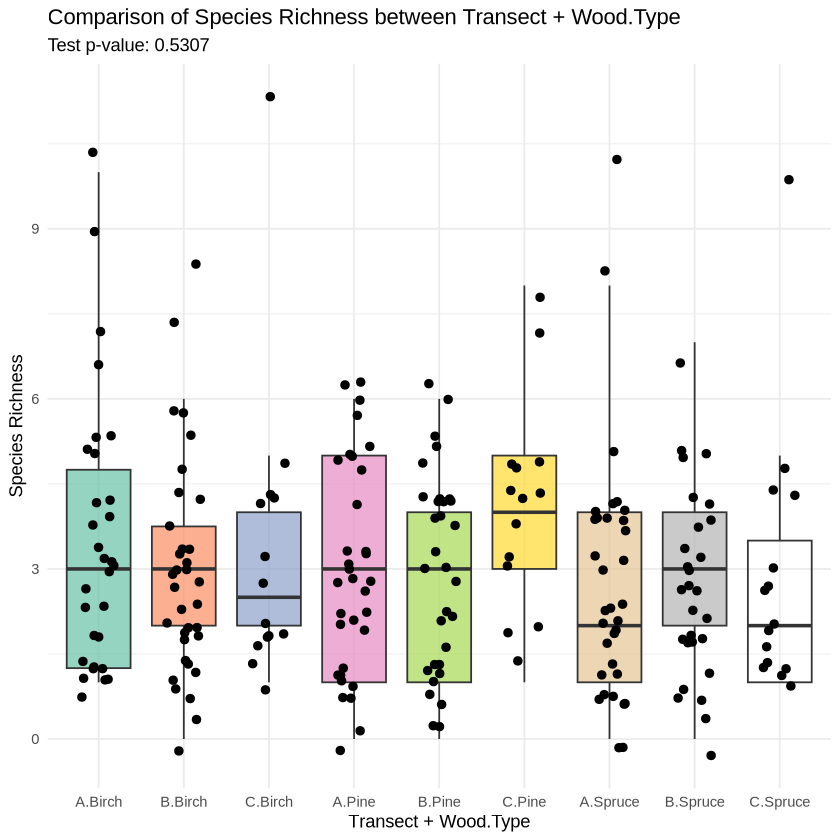

In [22]:
ggplot(analysis_df, aes(x = interaction(Transect, Wood.Type), y = richness, fill = interaction(Transect, Wood.Type))) +
  geom_boxplot(alpha = 0.7, outlier.shape = NA) +
  geom_jitter(width = 0.2, size = 2) + # Show individual data points
  theme_minimal() +
  labs(title = "Comparison of Species Richness between Transect + Wood.Type",
       subtitle = paste("Test p-value:", round(p.value, 4)),
       x = "Transect + Wood.Type",
       y = "Species Richness") +
  scale_fill_brewer(palette = "Set2") +
  theme(legend.position = "none")

#### 3.3.3. Statistical test - Shannon diversity

In [23]:
# Check for normality (Shapiro-Wilk test)
# If p > 0.05, use ANOVA. If p < 0.05, use Kruskal-Wallis.
shapiro_test <- shapiro.test(analysis_df$shannon)

p.value <- NULL
if(shapiro_test$p.value > 0.05) {
    # Parametric approach: ANOVA
    print("Parameteric")
    stat_result <- aov(shannon ~ Transect * Wood.Type, data = analysis_df)
    p.value <- summary(res)[[1]]["Pr(>F)", ]
    summary(stat_result)
} else {
    print("Non-parameteric")
    # Non-parametric approach: Kruskal-Wallis
    stat_result <- kruskal.test(shannon ~ interaction(Transect, Wood.Type), data = analysis_df)
    p.value <- stat_result$p.value
    print(stat_result)
}

[1] "Non-parameteric"

	Kruskal-Wallis rank sum test

data:  shannon by interaction(Transect, Wood.Type)
Kruskal-Wallis chi-squared = 4.1248, df = 8, p-value = 0.8457



#### 3.3.4. Visualization - Shannon diversity

Warning message in RColorBrewer::brewer.pal(n, pal):
“n too large, allowed maximum for palette Set2 is 8
Returning the palette you asked for with that many colors
”


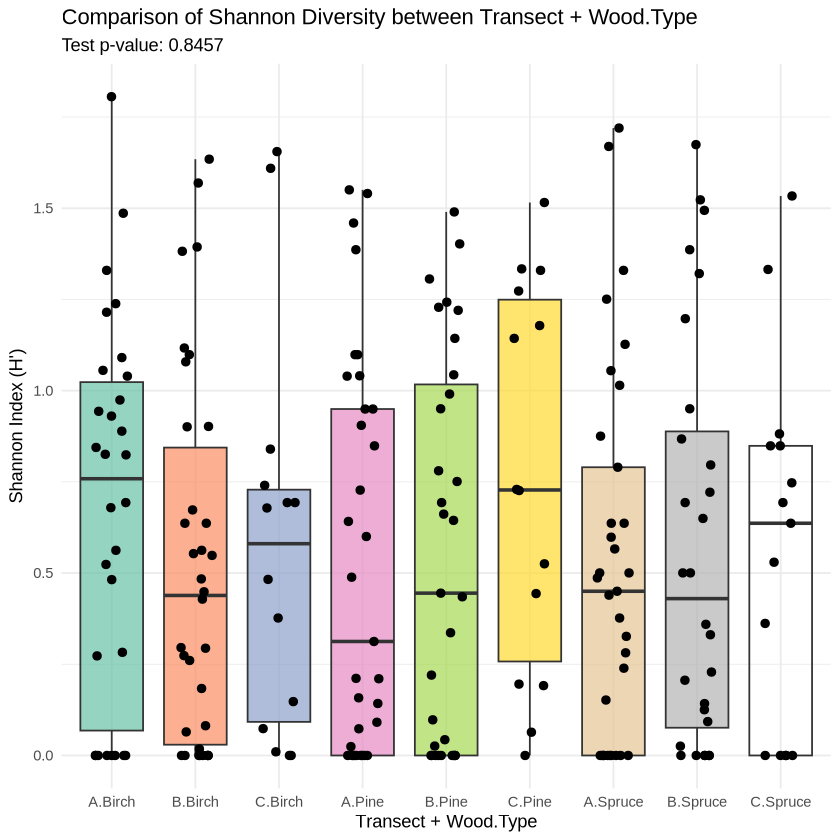

In [24]:
ggplot(analysis_df, aes(x = interaction(Transect, Wood.Type), y = shannon, fill = interaction(Transect, Wood.Type))) +
  geom_boxplot(alpha = 0.7, outlier.shape = NA) +
  geom_jitter(width = 0.2, size = 2) + # Show individual data points
  theme_minimal() +
  labs(title = "Comparison of Shannon Diversity between Transect + Wood.Type",
       subtitle = paste("Test p-value:", round(p.value, 4)),
       x = "Transect + Wood.Type",
       y = "Shannon Index (H')") +
  scale_fill_brewer(palette = "Set2") +
  theme(legend.position = "none")

#### 3.3.5. Statistical test - Simpson diversity

In [25]:
# Check for normality (Shapiro-Wilk test)
# If p > 0.05, use ANOVA. If p < 0.05, use Kruskal-Wallis.
shapiro_test <- shapiro.test(analysis_df$simpson)

p.value <- NULL
if(shapiro_test$p.value > 0.05) {
    # Parametric approach: ANOVA
    print("Parameteric")
    stat_result <- aov(simpson ~ Transect * Wood.Type, data = analysis_df)
    p.value <- summary(res)[[1]]["Pr(>F)", ]
    summary(stat_result)
} else {
    print("Non-parameteric")
    # Non-parametric approach: Kruskal-Wallis
    stat_result <- kruskal.test(simpson ~ interaction(Transect, Wood.Type), data = analysis_df)
    p.value <- stat_result$p.value
    print(stat_result)
}

[1] "Non-parameteric"

	Kruskal-Wallis rank sum test

data:  simpson by interaction(Transect, Wood.Type)
Kruskal-Wallis chi-squared = 1.4992, df = 8, p-value = 0.9927



#### 3.3.6. Visualization - Simpson diversity

Warning message in RColorBrewer::brewer.pal(n, pal):
“n too large, allowed maximum for palette Set2 is 8
Returning the palette you asked for with that many colors
”


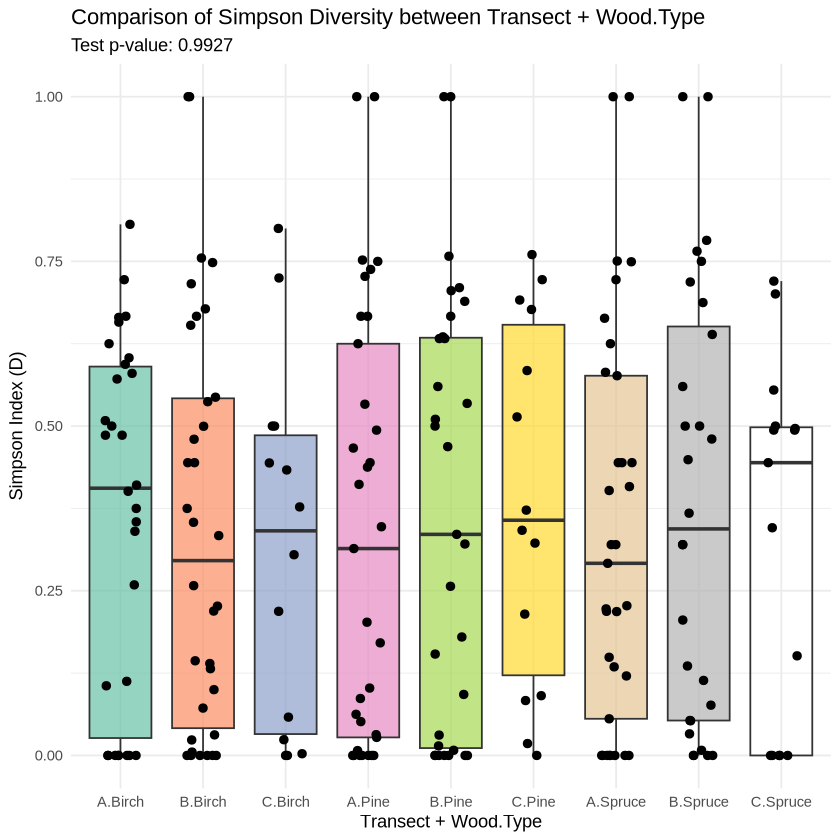

In [26]:
ggplot(analysis_df, aes(x = interaction(Transect, Wood.Type), y = simpson, fill = interaction(Transect, Wood.Type))) +
  geom_boxplot(alpha = 0.7, outlier.shape = NA) +
  geom_jitter(width = 0.2, size = 2) + # Show individual data points
  theme_minimal() +
  labs(title = "Comparison of Simpson Diversity between Transect + Wood.Type",
       subtitle = paste("Test p-value:", round(p.value, 4)),
       x = "Transect + Wood.Type",
       y = "Simpson Index (D)") +
  scale_fill_brewer(palette = "Set2") +
  theme(legend.position = "none")

## 4. Results

TODO